# 3. BERTopic results by publication

This notebook saves topic summaries and publication results for all six runs, then shows the
selected model if we have chosen one. We use these results to describe the articles in our dataset.
We have not tested the models on held-out articles yet.

Keep publication size, date coverage, repeated formatting, and the keyword search used to collect
articles in mind when interpreting the topics. The [comparison notebook](../../comparison/pipeline_comparison.ipynb)
brings together the LDA, BERTopic, and human-review results.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import display
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'pyproject.toml').exists())
ROOT = REPO/'final-project/code/modern-methods'
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT.parent))
from shared.corpus import corpus_hash, digest
from shared import evaluation as ev
from src import topic_helpers as h, artifacts as a
OUT = ROOT/'Results/modern'
OUT.mkdir(parents=True, exist_ok=True)

In [2]:
df, embeddings = h.load_inputs(ROOT)
reservation = json.loads((OUT/'review_sample.json').read_text())
assert reservation['corpus_hash'] == corpus_hash(df)
experiments = pd.read_csv(OUT/'experiments.csv')
selection = a.selection_record(OUT, df, experiments.run_id.tolist())
notebook = json.loads((ROOT/'notebooks/02_modern_topic_modeling.ipynb').read_text())
fit_source = ''.join(''.join(c['source']) for c in notebook['cells'] if 'model-fit' in c.get('metadata',{}).get('tags',[]))
current_implementation = digest([fit_source] + [(ROOT/p).read_text() for p in ['src/artifacts.py','src/topic_helpers.py','../shared/evaluation.py']])
# Verify current data and artifacts before exporting any run's evidence.
for run_id in experiments.run_id:
    folder = OUT/'runs'/run_id
    model_check, metrics_check = a.load_run(folder)
    identity = json.loads((folder/'manifest.json').read_text())['identity']
    assert identity['corpus_hash'] == corpus_hash(df) and identity['embedding_hash'] == a.array_hash(embeddings)
    assert identity['reservation_hash'] == digest(reservation)
    if identity['implementation_hash'] != current_implementation or identity['versions'] != a.environment()['versions']:
        raise ValueError('Experiment code or environment changed; rerun notebook 02 after preserving old runs')
    assignments = pd.read_csv(folder/'assignments.csv',dtype={'article_id':str})
    assert assignments.topic_id.tolist() == model_check.topics_
    inventory = a.topic_inventory(folder, folder, len(df))
    ev.publication_exports(df, assignments, folder/'publication',dict(zip(inventory.topic_id,inventory.label)))
print('Per-run topic inventories and publication outputs are complete.')

/Users/marykate/Desktop/F26/DataMiningProject/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Per-run topic inventories and publication outputs are complete.


## Topic shares by publication

The CSV tables include all 25 publications and every topic. The main heatmap shows publications
with at least 50 articles and the 15 largest topics, plus unassigned articles (−1).

Each cell is a topic's share of **all articles from that publication**, including unassigned
articles in the total. Since the figure leaves out smaller topics, its displayed shares may add
to less than 100%. These shares describe our sample, not everything a publication has published.

,topic_id,label,label_status,count,prevalence,coherence
0,-1,Unassigned,not a topic,1323,0.180442,NaN
1,0,0_tesla_autopilot_musk_teslas,keywords only; team interpretation pending,538,0.073377,0.695174
2,1,1_waymo_waymos_krafcik_selfdriving,keywords only; team interpretation pending,438,0.059738,0.729731
3,2,2_levandowski_uber_waymo_ubers,keywords only; team interpretation pending,334,0.045554,0.873680
4,3,3_cars_safety_human_car,keywords only; team interpretation pending,302,0.041189,0.680481
...,...,...,...,...,...,...
66,65,65_volvo_uber_xc90_selfdriving,keywords only; team interpretation pending,27,0.003682,0.652038
67,66,66_fiat_renault_chrysler_merger,keywords only; team interpretation pending,27,0.003682,0.912792
68,67,67_boundless_aired_hilltvs_5g,keywords only; team interpretation pending,27,0.003682,0.868196
69,68,68_vegas_las_shuttle_aptiv,keywords only; team interpretation pending,26,0.003546,0.691314


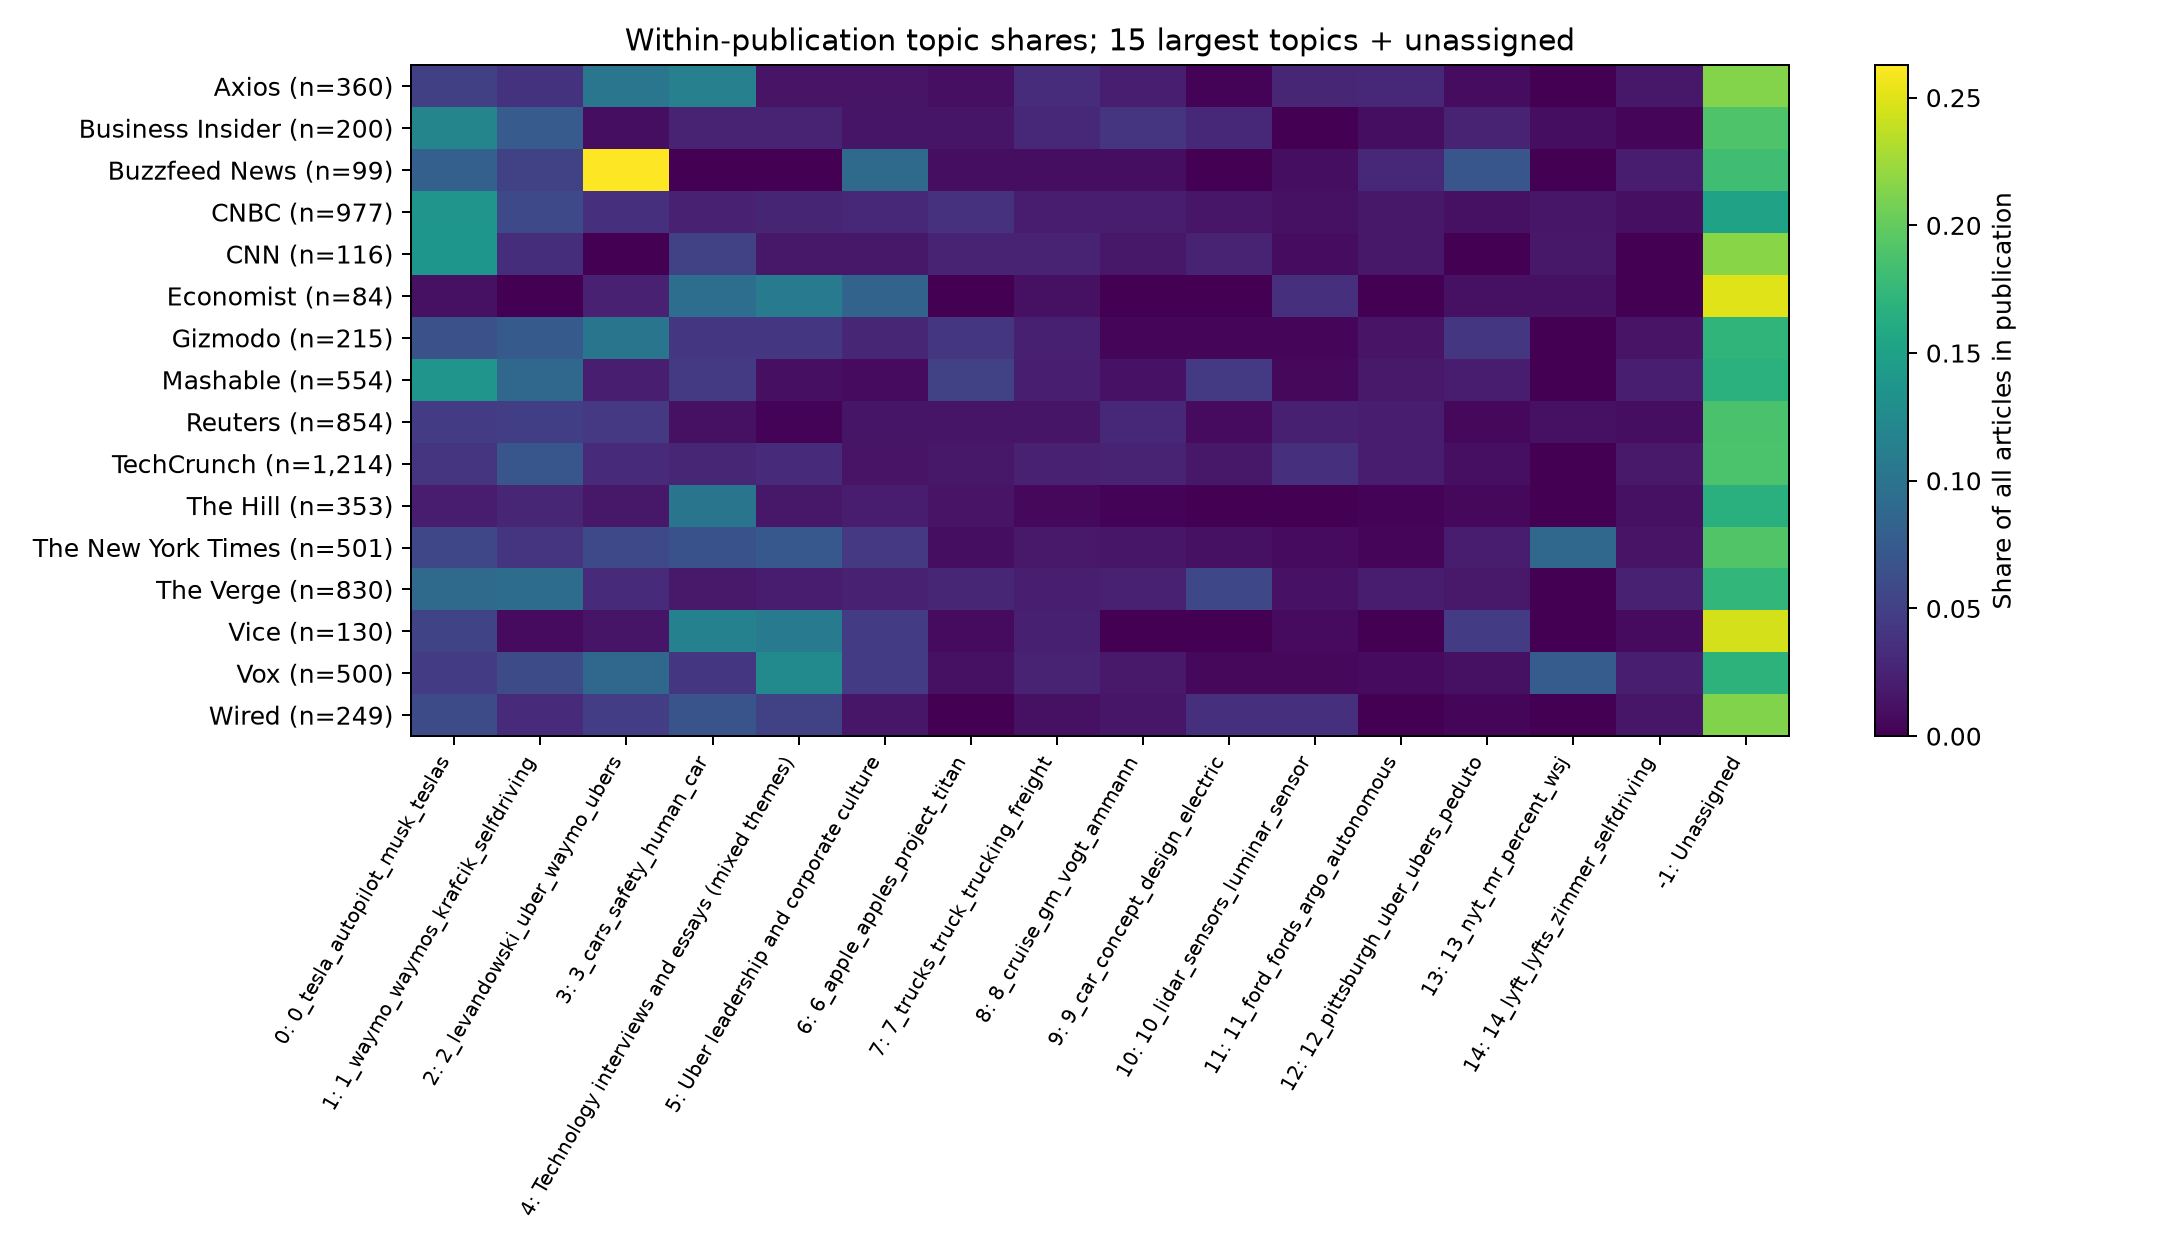

,seed,adjusted_rand_index,evaluated_count,evaluated_fraction,outlier_agreement,split_merge_threshold
0,7,0.961365,5697,0.777005,0.910393,At least two overlaps each covering >=10% of t...
1,21,0.976049,5678,0.774414,0.911348,At least two overlaps each covering >=10% of t...


Topic naming pending team confirmation; numeric outputs use provisional keyword labels.


In [3]:
modern = terms = inventory = labels = None
labels_ready = False
SELECTED = None
if selection is None:
    print('Selected-model interpretation pending: fill selection.json and rerun notebook 02.')
    display(experiments[['run_id','topic_count','coherence','outlier_fraction']])
else:
    run_id = selection['run_id']
    folder = OUT/'runs'/run_id
    SELECTED = OUT/'selected'/run_id
    SELECTED.mkdir(parents=True, exist_ok=True)
    manifest = json.loads((folder/'manifest.json').read_text())
    labels = a.labels_table(folder, SELECTED, {'run_id':run_id,'corpus_hash':corpus_hash(df),'run_identity_hash':digest(manifest['identity'])})
    labels_ready = bool(len(labels) and labels.confirmed.astype(str).str.lower().eq('true').all())
    modern = pd.read_csv(folder/'assignments.csv',dtype={'article_id':str})
    terms = pd.read_csv(folder/'terms.csv')
    inventory = a.topic_inventory(folder, SELECTED, len(df), labels)
    display(inventory[['topic_id','label','label_status','count','prevalence','coherence']])
    counts, proportions = ev.publication_exports(df, modern, SELECTED,dict(zip(inventory.topic_id,inventory.label)))
    from IPython.display import Image
    display(Image(filename=str(SELECTED/'publication_proportions.png')))
    if (SELECTED/'stability.csv').exists():
        display(pd.read_csv(SELECTED/'stability.csv'))
    else:
        print('Seed stability pending: rerun notebook 02 after selection.')
    if not labels_ready:
        print('Topic naming pending team confirmation; numeric outputs use provisional keyword labels.')

## Results to use in PR3

The tables below help us track what is ready for the report. We still need to write the
interpretation and update `pr3-submission.tex` ourselves.

- **Model comparison:** Six settings fit on the same 7,332 articles, with coherence and silhouette scores.
- **Topic summary:** Topic sizes, top ten words, coherence, and example articles. Use the final labels after team review.
- **Publication heatmap:** Topic shares for larger publications, with complete tables saved separately.
- **Stability:** ARI, the number of articles compared, and publication changes across seeds. Split/merge flags require at least two overlaps, each covering 10% of the source or target topic.

When writing the results, consider which themes the example articles support, which publications
differ, and whether date coverage could explain those differences. Also check whether any topics
mostly reflect transcripts or articles with little connection to autonomous vehicles.

In [4]:
evidence = pd.DataFrame([
    ('Data / methodology','Corpus, exclusions, embedding settings','complete','corpus_by_publication.csv; review_sample.json; cache manifest'),
    ('Experimental design / results','Six-configuration study','complete','experiments.csv'),
    ('Results / discussion','Team model choice','pending' if selection is None else 'complete','selection.json'),
    ('Results / discussion','Topic labels and article support','complete' if labels_ready else 'pending','selected/<run>/topic_labels.csv; topic_inventory.csv'),
    ('Results','Publication patterns','all grid runs complete; selected interpretation pending' if selection is None else 'selected run complete','runs/<run>/publication; selected/<run>/publication_proportions.csv'),
    ('Robustness','Selected configuration seeds 7 and 21','complete' if SELECTED is not None and (SELECTED/'stability.csv').exists() else 'pending','selected/<run>/stability.csv; seed_*/publication_changes.csv'),
    ('Limitations','Corpus bias, coverage, pooling, outliers','documented; team interpretation required','Notebook discussion prompts'),
    ('Response to feedback','PR2 feedback','available; response memo pending','final-project/progress-report-2/pr2-feedback.tex')
],columns=['manuscript_section','evidence','status','artifact'])

completion = pd.DataFrame([
    ('Confirm modern topic labels','Selection recorded; labels need team review' if selection is not None else 'Selection and labels pending','Mary Kate + team','selection rationale and confirmed labels','Team to confirm'),
    ('Interpret completed seed checks' if SELECTED is not None and (SELECTED/'stability.csv').exists() else 'Run chosen configuration with seeds 7 and 21','Assess assignment and publication-pattern stability','Mary Kate','ARI, outlier agreement, topic matches and publication changes','Team to confirm'),
    ('Modern held-out evaluation with rare-stratum policy','Assess transfer beyond fitted articles','Mary Kate','training-only fit and held-out metrics','Team to confirm'),
    ('Modern shared-period publication sensitivity','Assess unequal date coverage','Mary Kate + Lauren','date-restricted publication tables','Team to confirm'),
    ('Interpret findings and actual feedback','Support manuscript revision','Team','article-supported interpretations','Team to confirm')
],columns=['remaining_task','reason','responsible_member','expected_output','completion_date'])


# Separate November 25 follow-up evidence; does not confirm labels or ratings.
sys.path.insert(0, str(ROOT.parent/'comparison'))
from report_helpers import followup_checklists
evidence, completion = followup_checklists(evidence, completion, ROOT, corpus_hash(df))
evidence.to_csv(OUT/'pr3_evidence_checklist.csv', index=False)
completion.to_csv(OUT/'completion_plan.csv', index=False)
display(evidence, completion)


,manuscript_section,evidence,status,artifact
0,Data / methodology,"Corpus, exclusions, embedding settings",complete,corpus_by_publication.csv; review_sample.json;...
1,Experimental design / results,Six-configuration study,complete,experiments.csv
2,Results / discussion,Team model choice,complete,selection.json
3,Results / discussion,Topic labels and article support,pending,selected/<run>/topic_labels.csv; topic_invento...
4,Results,Publication patterns,selected run complete,runs/<run>/publication; selected/<run>/publica...
5,Robustness,Selected configuration seeds 7 and 21,complete,selected/<run>/stability.csv; seed_*/publicati...
6,Limitations,"Corpus bias, coverage, pooling, outliers",documented; team interpretation required,Notebook discussion prompts
7,Response to feedback,PR2 feedback,available; response memo pending,final-project/progress-report-2/pr2-feedback.tex
8,Robustness,Exploratory 80/20 split,computed; prior full-corpus development disclosed,Results/robustness/2026-11-25/split_metrics.cs...
9,Robustness,Shared-period publication sensitivity,computed; existing fits restricted to coverage...,Results/robustness/2026-11-25/shared_period/


,remaining_task,reason,responsible_member,expected_output,completion_date
0,Confirm modern topic labels,Selection recorded; labels need team review,Mary Kate + team,selection rationale and confirmed labels,Team to confirm
1,Interpret completed seed checks,Assess assignment and publication-pattern stab...,Mary Kate,"ARI, outlier agreement, topic matches and publ...",Team to confirm
2,Interpret findings and actual feedback,Support manuscript revision,Team,article-supported interpretations,Team to confirm
3,Resolve 30-article audit evidence,PR2 claim lacks saved judgments,Team,original judgments or new dated human audit,Team to confirm


## Work for the final report

We still plan to test held-out articles and compare publications over shared date ranges. Some
publication/year groups contain only one article, so we need a rule for splitting those groups.
For a held-out test, vocabulary building, model selection, and fitting must use only the training
articles. The current results use the full dataset.

Topic assignments alone do not measure sentiment, public opinion, or cause and effect. We also
need the actual PR2 feedback before writing a response to it. Our methods notes should explain
how we used AI for coding and planning, separately from the team's research decisions.